# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [5]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    select_existing_columns,
    summarize_pair_publication_rates,
)


## Configuration


In [7]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PARQUET_OUTPUT_DIR = OUTPUT_DIR / "parquets"
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = PARQUET_OUTPUT_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PARQUET_OUTPUT_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = PROJECT_ROOT / "assets" / "antibiotic_coarsening_lookup.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "Antibiotic" #Antibiotic,Class,Simplified categories,High level categories,Origin
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]

FIT_START_YEAR = 2000
FIT_END_YEAR = 2023
NUM_FUTURE_YEARS = 5

MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = 5.0
MIN_CURRENT_PREDICTED_COUNT = 10
MIN_FUTURE_PREDICTED_COUNT = 10
MIN_SI_CHANGE = 0.07
MIN_POST_FIT_OBSERVED_YEARS = 1
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 750.0
FALLBACK_TOP_N = 10

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_LOOKBACK_YEARS = 5
MAX_DRIVER_PLOTS = 25
MAX_INTERESTING_PLOTS = 25
FIGURE_FORMAT = "pdf"
DISPLAY_PLOTS = True
MAX_DISPLAY_PLOTS = 10
FILL_MISSING_AMR_COUNTS_WITH_ZERO = True
PLOT_END_YEAR = FIT_END_YEAR + NUM_FUTURE_YEARS


## Load Canonical Inputs


In [8]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 7,602
yearly_screened unique pathogens: 10
yearly_screened unique antibiotics: 183
yearly_screened year range: 2000 - 2026
pathogen bg rows: 270
antibiotic bg rows: 4,941
unified decision rows available for driver analysis: 54,740


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [9]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 7,602
model pathogen-antibiotic rows: 828
model antibiotic values: 183
model antibiotic background rows: 4,941
model unified decision rows: 54,740


,pathogen,antibiotic,year,pmids,count
0,Borrelia burgdorferi,Amikacin,2003,[12559574],1
1,Borrelia burgdorferi,Amoxicillin,2006,[17160604],1
2,Borrelia burgdorferi,Amoxicillin,2025,[40692686],1
3,Borrelia burgdorferi,Azithromycin,2000,[10706176],1
4,Borrelia burgdorferi,Azithromycin,2006,[17160604],1
5,Borrelia burgdorferi,Azithromycin,2025,[40692686],1
6,Borrelia burgdorferi,Azlocillin,2000,[10706176],1
7,Borrelia burgdorferi,Benzylpenicillin,2000,[10706176],1
8,Borrelia burgdorferi,Cefoperazone,2015,[26716015],1
9,Borrelia burgdorferi,Cefoperazone,2017,[29186026],1


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [10]:
yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 91 / 828 pairs with >= 5 publications/year on average from 2000 to 2023.


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
221,Helicobacter pylori,Clarithromycin,1047,43.625000
485,Pseudomonas aeruginosa,Ciprofloxacin,791,32.958333
237,Helicobacter pylori,Metronidazole,787,32.791667
206,Helicobacter pylori,Amoxicillin,748,31.166667
476,Pseudomonas aeruginosa,Ceftazidime,652,27.166667
575,Salmonella enterica,Ampicillin,639,26.625000
670,Salmonella enterica,Tetracycline,598,24.916667
519,Pseudomonas aeruginosa,Meropenem,561,23.375000
604,Salmonella enterica,Ciprofloxacin,556,23.166667
722,Streptococcus pneumoniae,Erythromycin,553,23.041667


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [11]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_df.head(10)


SI rows: 2,355
SI pairs: 91


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Clostridioides difficile,Clindamycin,2002,[12385683],1,177,182,0.301030,2.250420,2.262451,0.129213,0.346521,0.171817
1,Clostridioides difficile,Clindamycin,2003,[12958245],1,200,240,0.301030,2.303196,2.382017,0.219820,0.658900,0.081210
2,Clostridioides difficile,Clindamycin,2004,"[14986247, 15496392]",2,177,245,0.477121,2.250420,2.390935,0.173043,0.489508,0.304079
3,Clostridioides difficile,Clindamycin,2007,"[17509804, 17577057, 17995898]",3,319,301,0.602060,2.505150,2.480007,0.443888,1.779000,0.158172
4,Clostridioides difficile,Clindamycin,2008,[18761903],1,401,315,0.301030,2.604226,2.499687,0.544128,2.500484,-0.243098
5,Clostridioides difficile,Clindamycin,2009,[19097757],1,466,287,0.301030,2.669317,2.459392,0.591827,2.906854,-0.290797
6,Clostridioides difficile,Clindamycin,2010,"[19406247, 19942691, 20890081]",3,522,291,0.602060,2.718502,2.465383,0.640300,3.368178,-0.038240
7,Clostridioides difficile,Clindamycin,2011,"[21712239, 21747423, 21771851]",3,589,316,0.602060,2.770852,2.501059,0.701888,4.033712,-0.099828
8,Clostridioides difficile,Clindamycin,2012,"[22411613, 22710106, 23072056]",3,714,344,0.602060,2.854306,2.537819,0.793207,5.211656,-0.191147
9,Clostridioides difficile,Clindamycin,2013,[24578839],1,897,309,0.301030,2.953276,2.491362,0.870786,6.426529,-0.569756


## Rank Reliable Future High-Interest Pairs


In [12]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/91] ranking Clostridioides difficile vs Clindamycin
[2/91] ranking Clostridioides difficile vs Metronidazole
[3/91] ranking Clostridioides difficile vs Vancomycin
[4/91] ranking Haemophilus influenzae vs Amoxicillin
[5/91] ranking Haemophilus influenzae vs Ampicillin
[6/91] ranking Helicobacter pylori vs Amoxicillin
[7/91] ranking Helicobacter pylori vs Clarithromycin
[8/91] ranking Helicobacter pylori vs Levofloxacin
[9/91] ranking Helicobacter pylori vs Metronidazole
[10/91] ranking Helicobacter pylori vs Tetracycline
[11/91] ranking Klebsiella pneumoniae vs Amikacin
[12/91] ranking Klebsiella pneumoniae vs Amoxicillin
[13/91] ranking Klebsiella pneumoniae vs Ampicillin
[14/91] ranking Klebsiella pneumoniae vs Cefepime
[15/91] ranking Klebsiella pneumoniae vs Cefotaxime
[16/91] ranking Klebsiella pneumoniae vs Ceftazidime
[17/91] ranking Klebsiella pneumoniae vs Ceftazidime/avibactam
[18/91] ranking Klebsiella pneumoniae vs Ceftolozane/tazobactam
[19/91] ranking Klebsiella pneumon

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Ceftazidime/avibactam,0.241078,0.405538,38.177862,160.309880,35.480660
1,Klebsiella pneumoniae,Amoxicillin,0.115640,0.204575,31.384397,99.998261,75.967040
2,Klebsiella pneumoniae,Nitrofurantoin,0.109921,0.230499,24.268109,83.484503,262.237220
3,Salmonella enterica,Azithromycin,0.108652,0.194139,23.050564,47.971011,38.572247
4,Pseudomonas aeruginosa,Amoxicillin,0.107424,0.221243,20.045726,55.470127,210.963025
5,Mycobacterium tuberculosis,Rifampicin,0.105356,0.185524,23.603881,41.484302,21.234901
6,Klebsiella pneumoniae,Colistin,0.097577,0.146020,106.560242,276.148951,26.229674
7,Pseudomonas aeruginosa,Tazobactam,0.092056,0.148077,74.134242,173.269558,75.921986
8,Salmonella enterica,Ceftriaxone,0.087920,0.169417,30.771180,61.076321,189.685007
9,Streptococcus pneumoniae,Tetracycline,0.081466,0.150583,17.574416,29.775371,40.964536


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [13]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Klebsiella pneumoniae,Ceftazidime/avibactam,0.241078,0.405538,38.177862,160.309880,110,91,RESISTANCE_MECHANISM,RESISTANCE_MECHANISM,0.009091,0.881818
1,Klebsiella pneumoniae,Amoxicillin,0.115640,0.204575,31.384397,99.998261,109,70,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.880734
2,Klebsiella pneumoniae,Nitrofurantoin,0.109921,0.230499,24.268109,83.484503,82,59,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.890244
3,Salmonella enterica,Azithromycin,0.108652,0.194139,23.050564,47.971011,87,57,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.965517
4,Pseudomonas aeruginosa,Amoxicillin,0.107424,0.221243,20.045726,55.470127,69,45,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.898551
5,Mycobacterium tuberculosis,Rifampicin,0.105356,0.185524,23.603881,41.484302,92,36,RESISTANCE_MECHANISM,RESISTANCE_MECHANISM,0.032609,0.793478
6,Klebsiella pneumoniae,Colistin,0.097577,0.146020,106.560242,276.148951,376,260,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.005319,0.901596
7,Pseudomonas aeruginosa,Tazobactam,0.092056,0.148077,74.134242,173.269558,273,159,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.003663,0.754579
8,Salmonella enterica,Ceftriaxone,0.087920,0.169417,30.771180,61.076321,115,53,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.886957
9,Streptococcus pneumoniae,Tetracycline,0.081466,0.150583,17.574416,29.775371,76,30,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.802632


## Plot Category Driver Curves


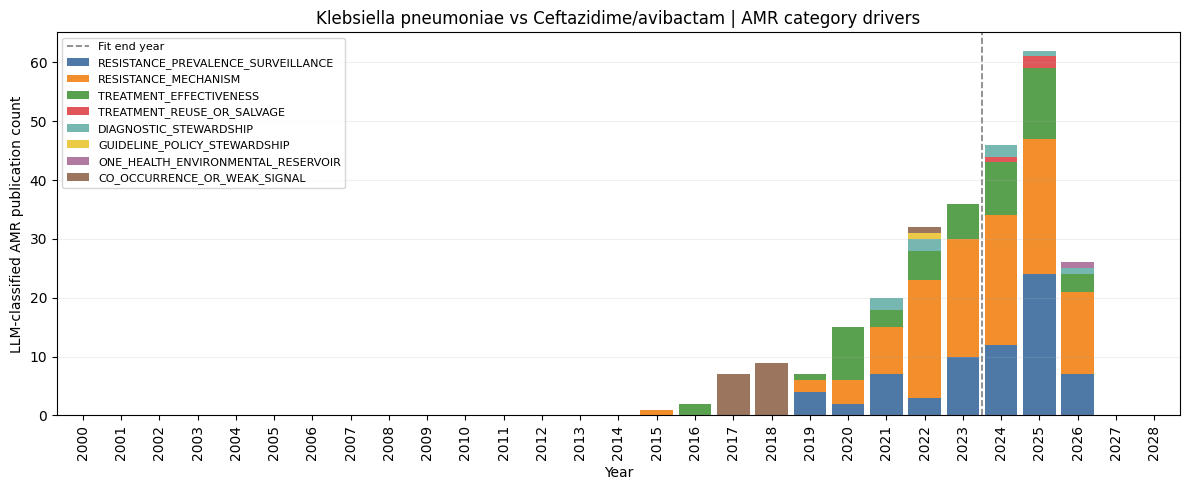

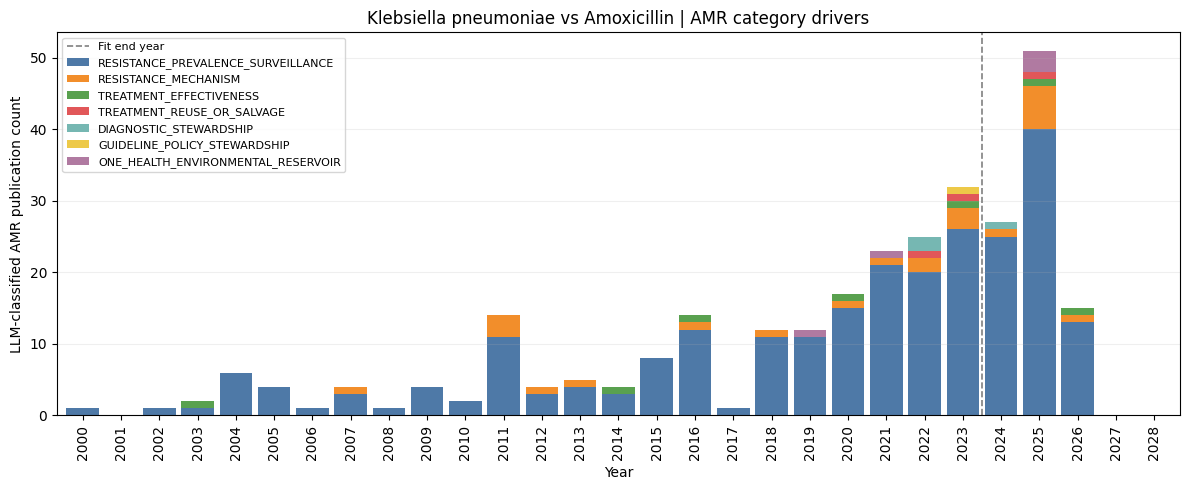

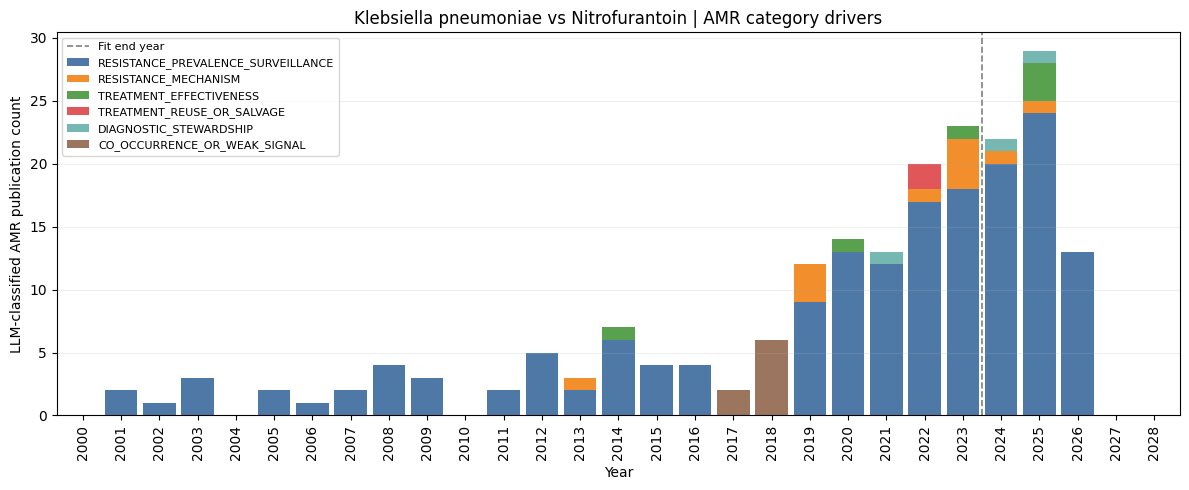

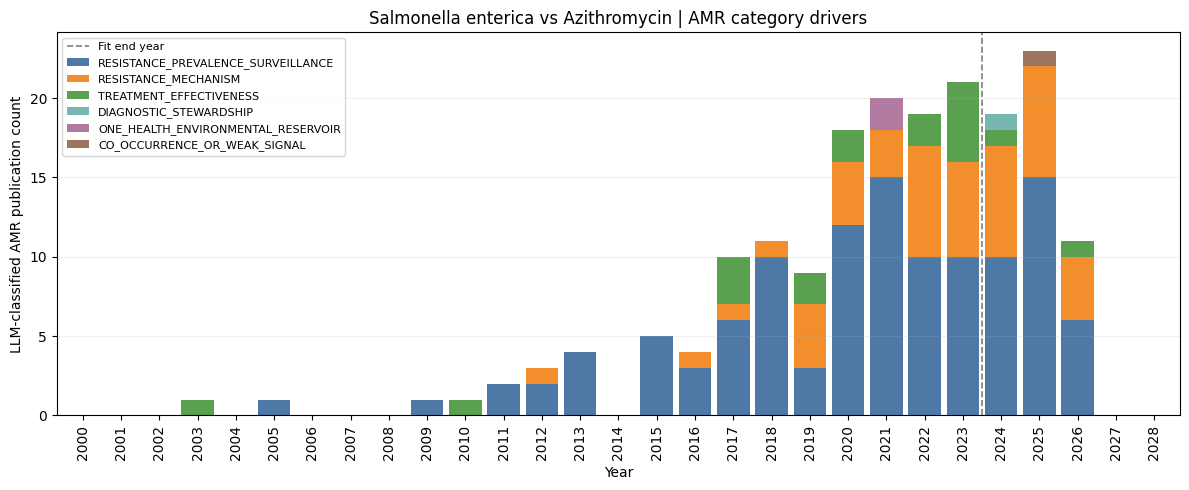

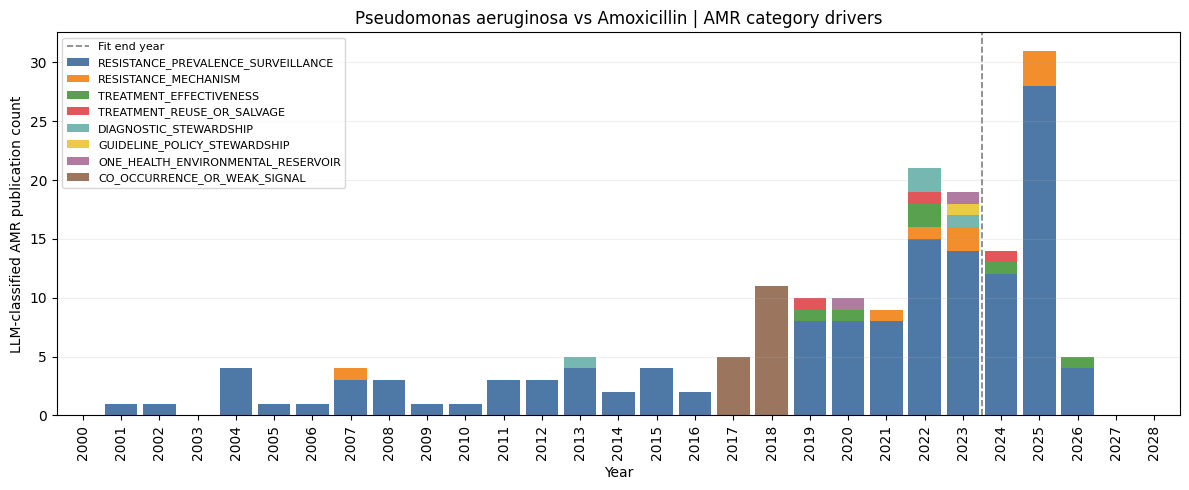

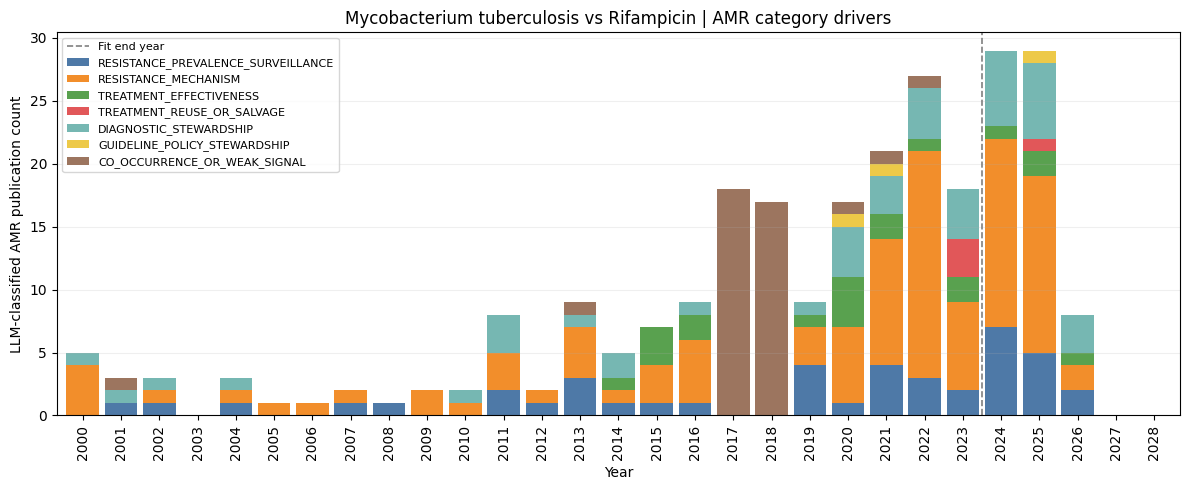

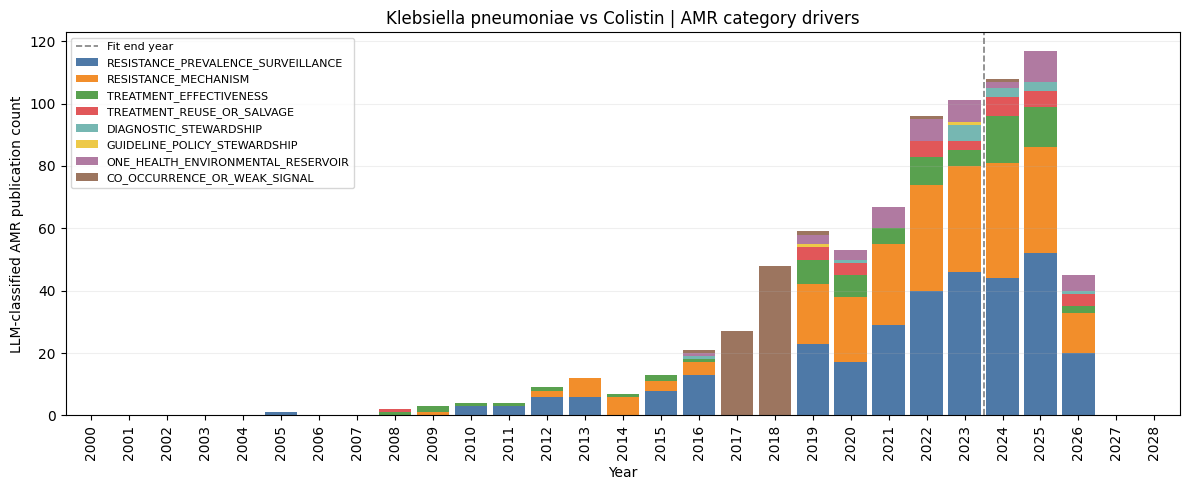

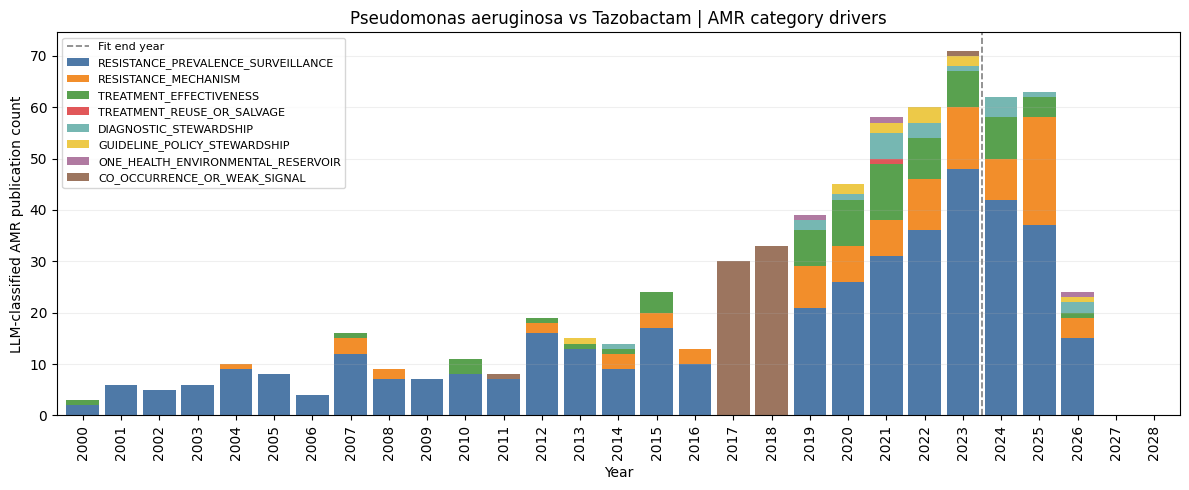

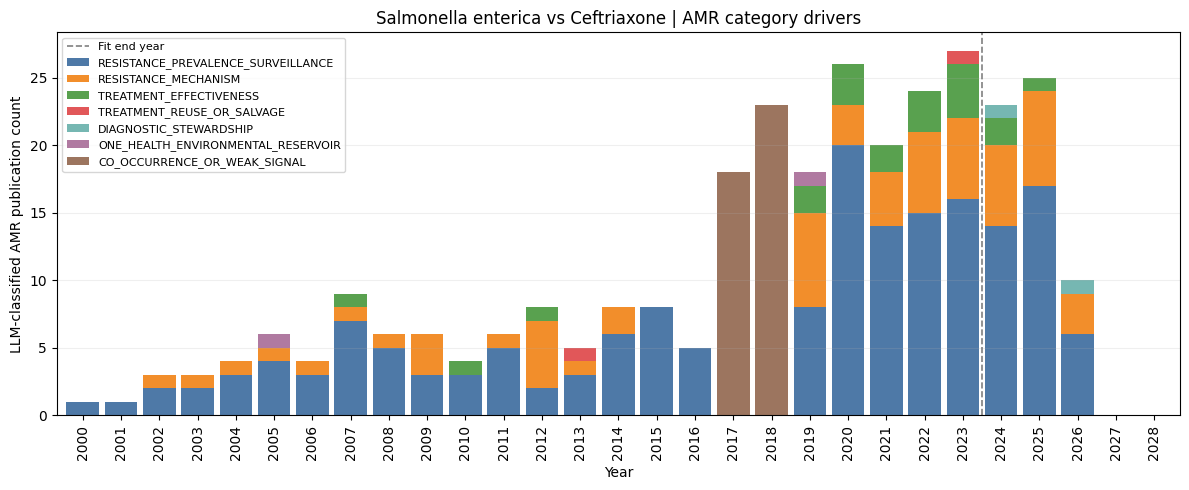

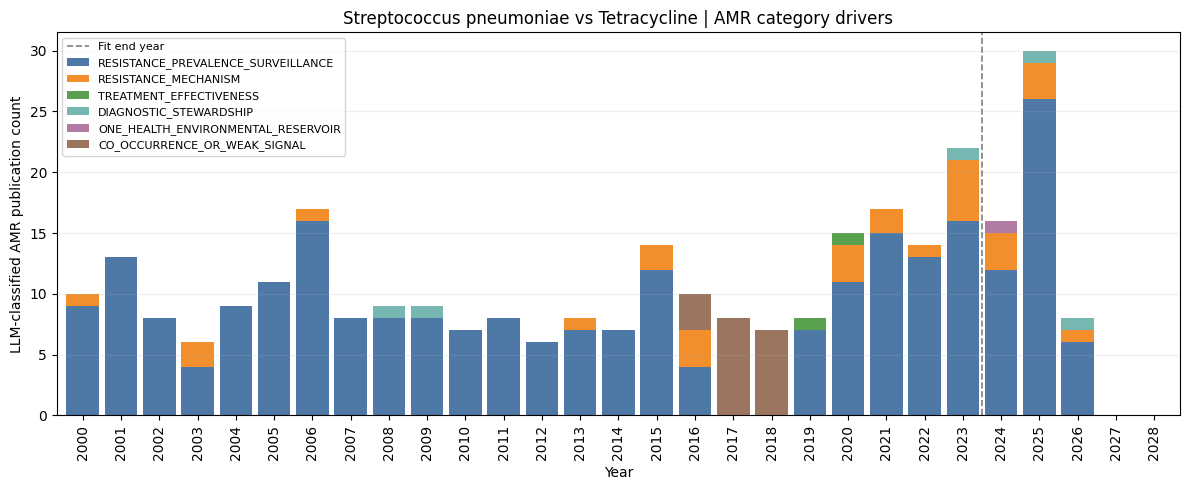

Saved 25 category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.


In [14]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


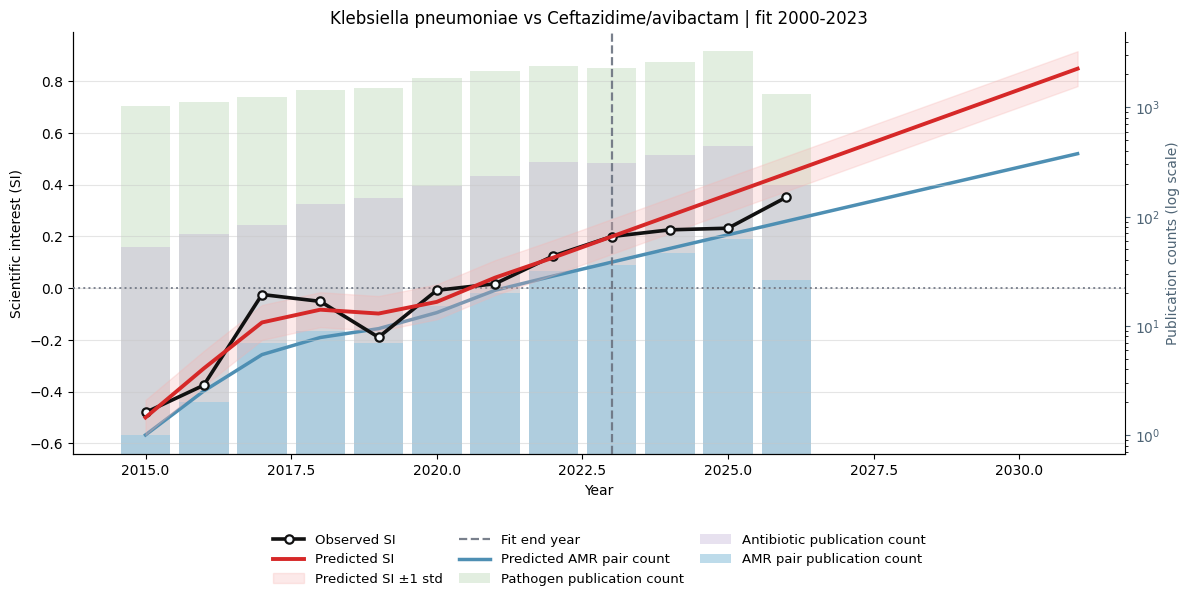

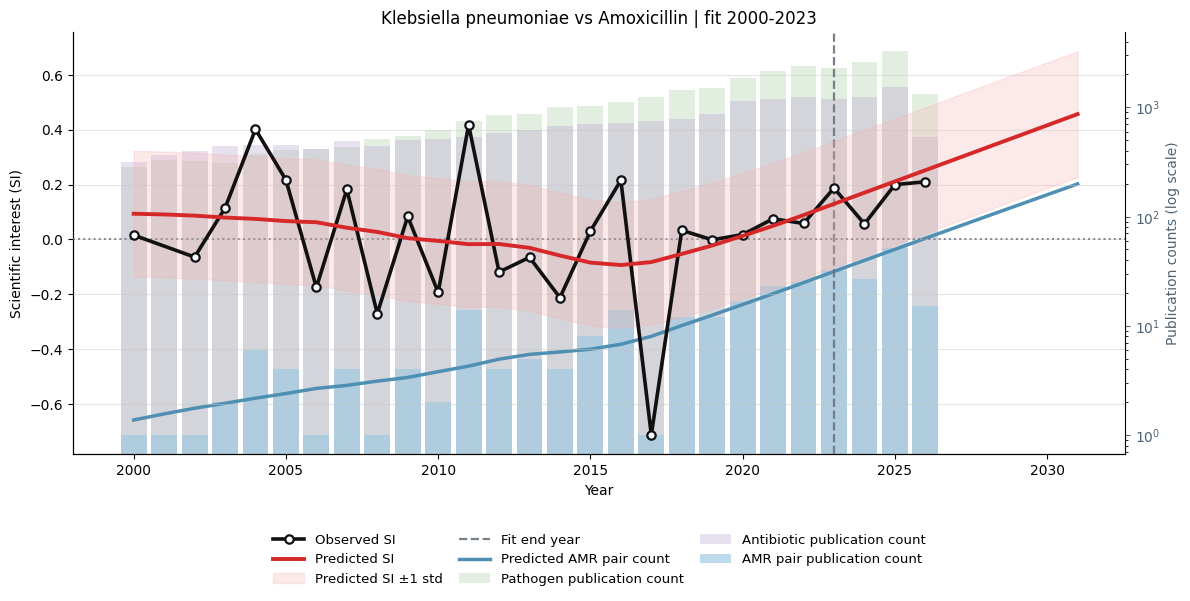

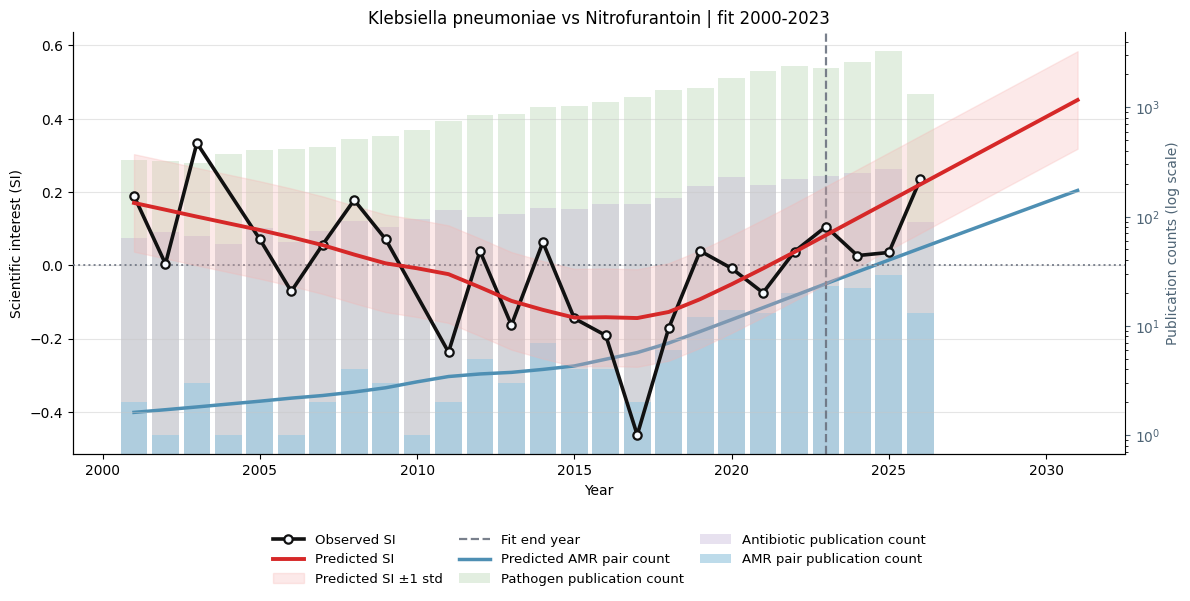

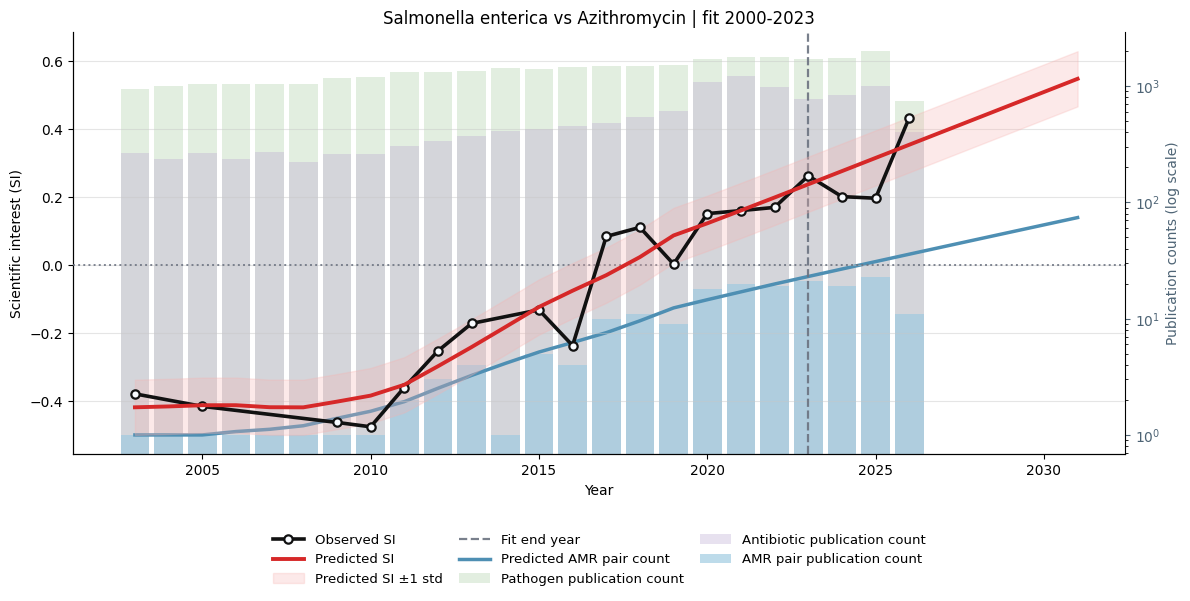

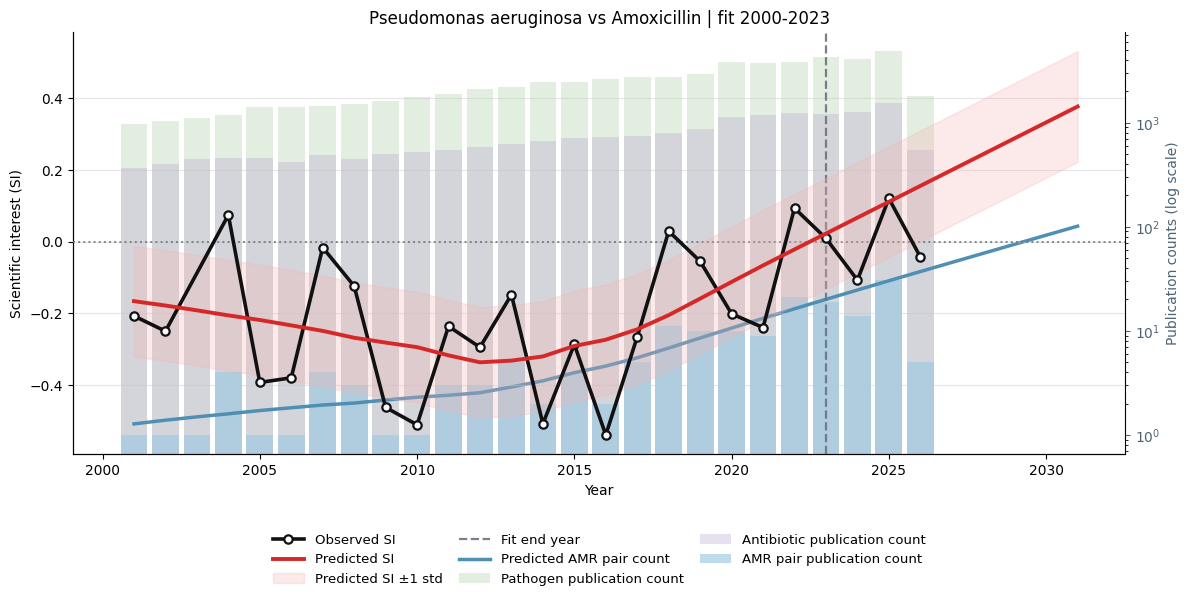

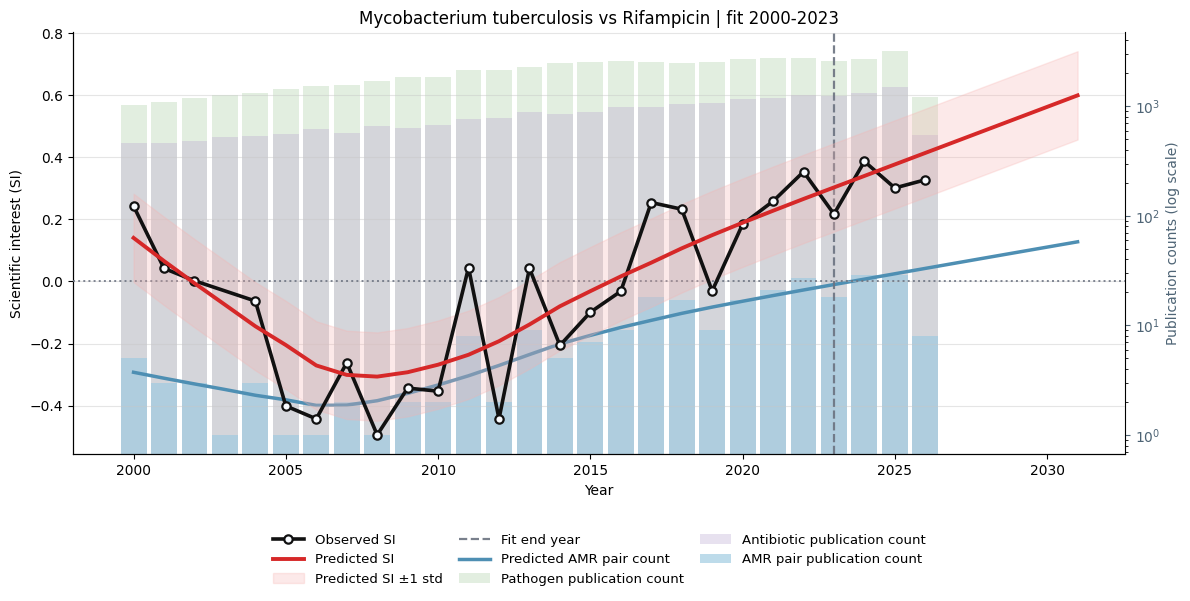

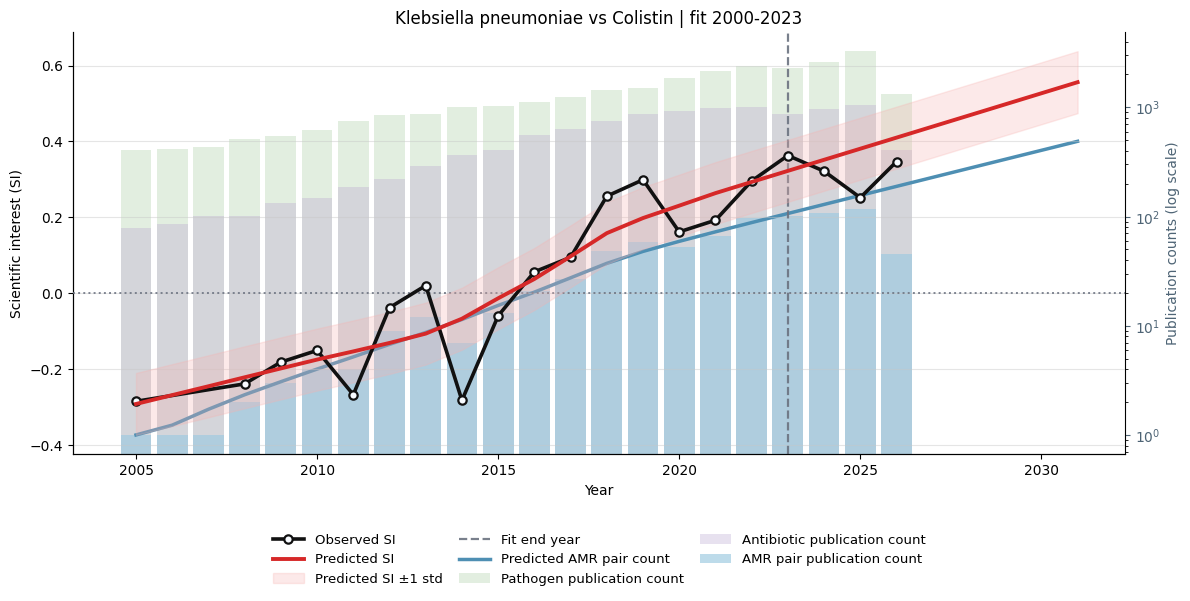

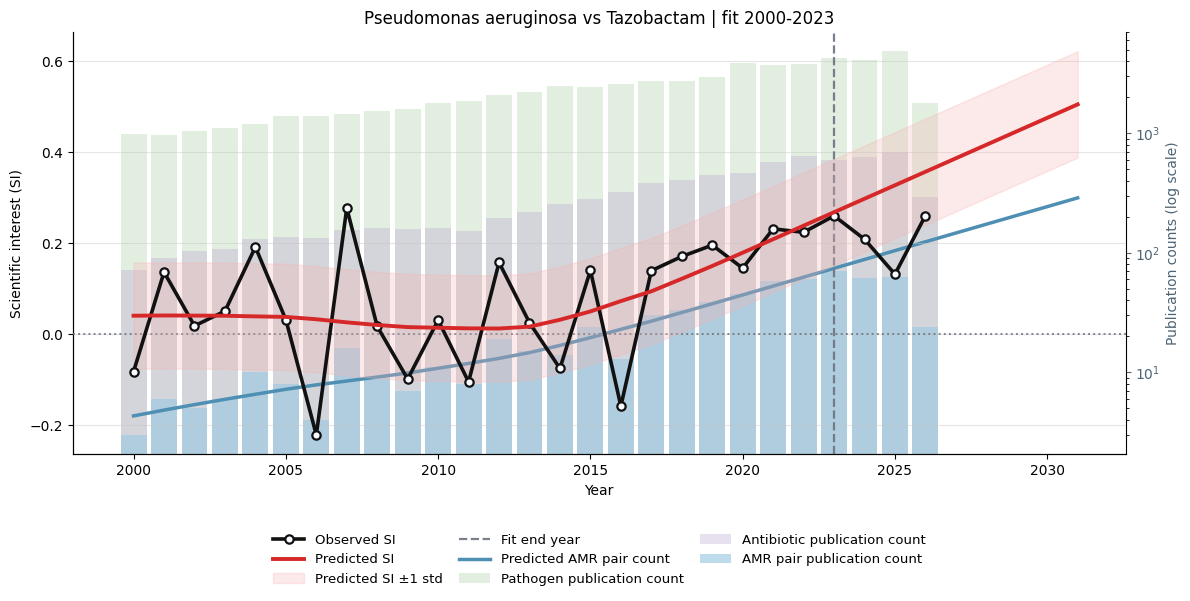

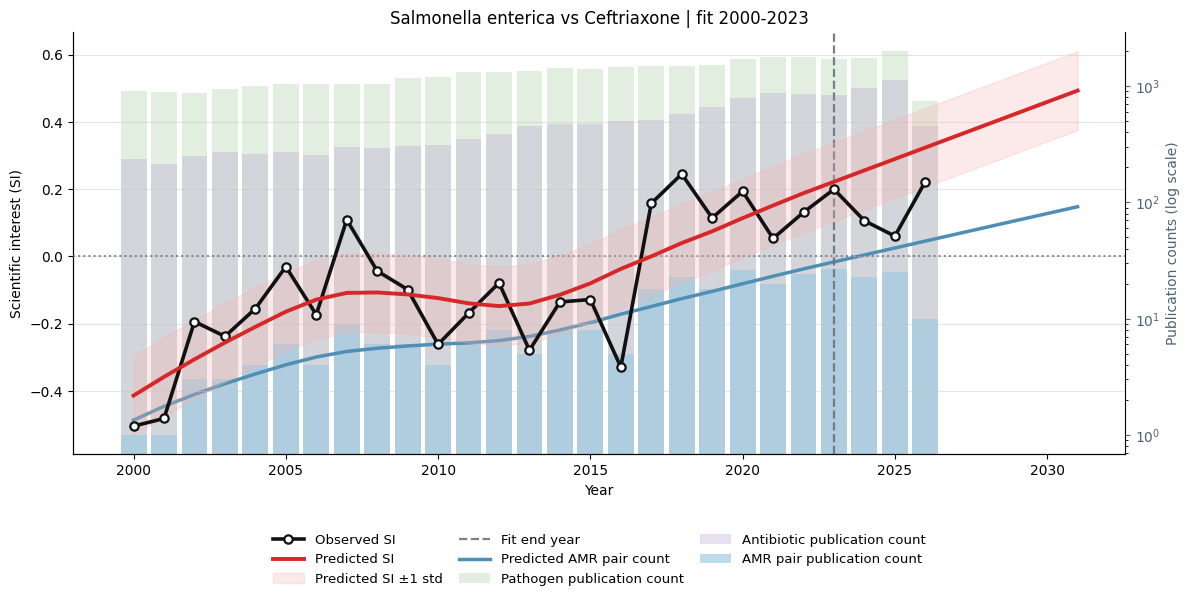

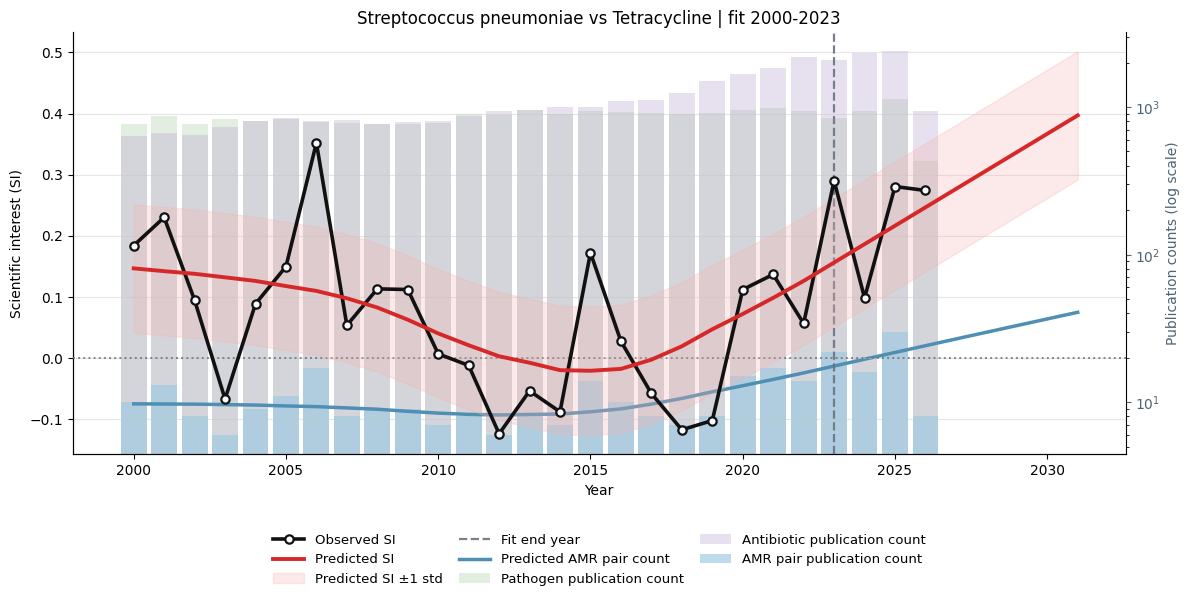

Saved 25 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [15]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)
